# Push-T RGB PPO: joint control, 50M transitions, 32 minibatches

Train a **fresh camera-based teacher** with ManiSkill's original `ppo_rgb.py`. Both actor and critic use the baseline's shared RGB/proprioception encoder. Inputs include joint positions/velocities and stick-tip pose (`tcp_pose`), but exclude numerical block and target poses. Actions are joint-angle increments (`pd_joint_delta_pos`). No frame history, custom reward, or custom observation adapter is used.

Select **Runtime → Change runtime type → L4 GPU**. Run cells in order: setup, observation check, smoke test, then training. This notebook is self-contained; upload only this file. It uses a separate Python 3.11 environment even when the Colab kernel is Python 3.13.

The main budget is **50,000,000 requested transitions**, starting from random weights. PPO processes complete batches; with the default 1024 × 16 batch it executes **49,987,584 transitions**. Use **32 minibatches of 512 samples**, matching the baseline batch configuration. Compared with the completed 1024-environment run, only the minibatch count changes (8 → 32), along with the run name. Reward, learning rate, seed, and other training settings stay the same. This tests the configuration difference; it does not guarantee that late collapse will disappear.

The progress bar reports the latest periodic evaluation's **success once, success at end, return, and cumulative SPS**, together. A CSV preserves every evaluation. These are periodic validation estimates, not final test results.


In [ ]:
from pathlib import Path
import os, sys, json, subprocess, datetime, hashlib, shlex, shutil, time, csv

MANISKILL_COMMIT = "a4a4f9272ad64b1564035874b605ceb687b63ed8"  # v3.0.1
MS_ROOT = Path("/content/ManiSkill")
WORK_ROOT = Path("/content/pusht_camera_ppo")  # Reuses the earlier Python 3.11 environment, if present.
WORK_ROOT.mkdir(parents=True, exist_ok=True)
USE_GOOGLE_DRIVE = True
SEED = 1
NUM_ENVS = 1024
NUM_STEPS = 16
NUM_MINIBATCHES = 32
UPDATE_EPOCHS = 8
NUM_EVAL_ENVS = 16
EVAL_FREQ = 25  # Must exceed 1 for the upstream modulo convention.
TOTAL_TRANSITIONS = 50_000_000
RUN_NAME = "rgb_joint_seed1_50m_mb32"
SESSION = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
subprocess.run(["nvidia-smi"], check=True)
print("Notebook Python:", sys.version)


Notebook Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


## 1. Save outputs to Drive

Every session gets a new output folder. Checkpoints, logs, CSV metrics, package versions, baseline source, and the observation contract are saved there. Source/installations/assets stay on Colab's local disk. With Drive disabled, outputs are temporary until downloaded. Reuse this cell's variables rather than rerunning it during training.


In [ ]:
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/182_final_project/camera_ppo_joint") / SESSION
else:
    OUTPUT_ROOT = WORK_ROOT / "joint_outputs" / SESSION
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
print("Output directory:", OUTPUT_ROOT)


Mounted at /content/drive
Output directory: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z


## 2. Install the pinned baseline under Python 3.11

This isolates simulator dependencies from Colab's notebook kernel. Full command output is streamed and saved to `setup.log`; failures show the underlying error. CUDA PyTorch, NumPy, OpenCV, and SAPIEN are pinned; `pip-freeze.txt` records all resolved versions. Existing working Python 3.11 installations are reused. This does not switch the notebook kernel.


In [ ]:
SETUP_LOG = OUTPUT_ROOT / "setup.log"

def checked(command, **kwargs):
    command = list(map(str, command))
    print(shlex.join(command), flush=True)
    tail = []
    with SETUP_LOG.open("a") as log:
        log.write("\n$ " + shlex.join(command) + "\n")
        with subprocess.Popen(command, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True,
                              bufsize=1, **kwargs) as process:
            try:
                for line in process.stdout:
                    print(line, end="", flush=True)
                    log.write(line)
                    log.flush()
                    tail.append(line.rstrip())
                    tail = tail[-40:]
                result = process.wait()
            except BaseException:
                process.terminate()
                try:
                    process.wait(timeout=15)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
                raise
        if result:
            raise RuntimeError(
                f"Command failed (exit {result}). Full log: {SETUP_LOG}\n"
                + "\n".join(tail)
            )

checked(["apt-get", "update", "-qq"])
checked(["apt-get", "install", "-y", "libvulkan1", "libvulkan-dev", "vulkan-tools", "libglvnd-dev"])
if not (MS_ROOT / ".git").exists():
    checked(["git", "clone", "https://github.com/mani-skill/ManiSkill.git", MS_ROOT])
checked(["git", "-C", MS_ROOT, "checkout", "--detach", MANISKILL_COMMIT])
actual_commit = subprocess.check_output(["git", "-C", str(MS_ROOT), "rev-parse", "HEAD"], text=True).strip()
assert actual_commit == MANISKILL_COMMIT

# Only uv is installed in the notebook kernel. Simulator dependencies
# and CUDA PyTorch are installed in the separate training interpreter.
checked([sys.executable, "-m", "pip", "install", "uv==0.9.11", "tqdm==4.67.1", "ipywidgets>=8,<9"])
TRAIN_ENV = WORK_ROOT / "python311"
TRAIN_PY = TRAIN_ENV / "bin/python"
if not TRAIN_PY.exists():
    checked([sys.executable, "-m", "uv", "venv", "--python", "3.11", "--seed", TRAIN_ENV])
checked([TRAIN_PY, "-c", "import sys; print(sys.version); assert sys.version_info[:2] == (3, 11)"])

constraints = WORK_ROOT / "constraints.txt"
constraints.write_text("numpy==1.26.4\nopencv-python==4.11.0.86\nsapien==3.0.3\ntorch==2.6.0\n")
shutil.copy2(constraints, OUTPUT_ROOT / "constraints.txt")
checked([TRAIN_PY, "-m", "pip", "install", "torch==2.6.0",
         "--index-url", "https://download.pytorch.org/whl/cu124"])
# Probe compiled wheels under Python 3.11 before the large install.
checked([TRAIN_PY, "-m", "pip", "download", "--only-binary=:all:", "--no-deps",
         "--dest", WORK_ROOT / "wheel_check", "mplib==0.1.1", "sapien==3.0.3"])
checked([TRAIN_PY, "-m", "pip", "install", "--constraint", constraints,
         "-e", MS_ROOT, "numpy", "opencv-python", "sapien",
         "tyro", "tensorboard", "wandb", "matplotlib", "imageio[ffmpeg]", "pillow"])
checked([TRAIN_PY, "-m", "pip", "check"])

for filename, library, vulkan in [
    ("/usr/share/vulkan/icd.d/nvidia_icd.json", "libGLX_nvidia.so.0", True),
    ("/usr/share/glvnd/egl_vendor.d/10_nvidia.json", "libEGL_nvidia.so.0", False),
]:
    path = Path(filename)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        icd = {"library_path": library}
        if vulkan:
            icd["api_version"] = "1.2.155"
        path.write_text(json.dumps({"file_format_version": "1.0.0", "ICD": icd}))
os.environ["VK_ICD_FILENAMES"] = "/usr/share/vulkan/icd.d/nvidia_icd.json"
os.environ["MANISKILL_ROOT"] = str(MS_ROOT)
os.environ["MS_SKIP_ASSET_DOWNLOAD_PROMPT"] = "1"
os.environ["PYTHONUNBUFFERED"] = "1"
checked(["vulkaninfo", "--summary"])
checked([TRAIN_PY, "-c", "import torch, sapien, mplib, mani_skill, numpy; print('torch:', torch.__version__); print('CUDA:', torch.version.cuda); print('NumPy:', numpy.__version__); assert torch.cuda.is_available(); print(torch.cuda.get_device_name(0))"])
(OUTPUT_ROOT / "pip-freeze.txt").write_text(subprocess.check_output([str(TRAIN_PY), "-m", "pip", "freeze"], text=True))
(OUTPUT_ROOT / "training-python.txt").write_text(subprocess.check_output([str(TRAIN_PY), "--version"], text=True))
(OUTPUT_ROOT / "nvidia-smi.txt").write_text(subprocess.check_output(["nvidia-smi"], text=True))

BASELINE = MS_ROOT / "examples/baselines/ppo/ppo_rgb.py"
assert BASELINE.is_file()
shutil.copy2(BASELINE, OUTPUT_ROOT / "upstream_ppo_rgb.py")
BASELINE_SHA256 = hashlib.sha256(BASELINE.read_bytes()).hexdigest()
help_result = subprocess.run([str(TRAIN_PY), str(BASELINE), "--help"],
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
(OUTPUT_ROOT / "baseline-help.txt").write_text(help_result.stdout)
if help_result.returncode:
    raise RuntimeError(help_result.stdout)
print("Training Python:", TRAIN_PY)
print("Pinned commit:", actual_commit)


apt-get update -qq
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
apt-get install -y libvulkan1 libvulkan-dev vulkan-tools libglvnd-dev
Reading package lists...
Building dependency tree...
Reading state information...
libvulkan1 is already the newest version (1.3.275.0-1build1).
libvulkan1 set to manually installed.
The following additional packages will be installed:
  libegl-dev libgl-dev libgles-dev libgles1 libglvnd-core-dev libglx-dev
  libopengl-dev
The following NEW packages will be installed:
  libegl-dev libgl-dev libgles-dev libgles1 libglvnd-core-dev libglvnd-dev
  libglx-dev libopengl-dev libvulkan-dev vulkan-tools
0 upgraded, 10 newly installed, 0 to remove and 114 not upgraded.
Need to get 1,754 kB of archives.
After this operation, 30.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd6

## 3. Verify actual inputs and render the policy camera

The check runs in a child process under Python 3.11. It verifies the installed baseline defaults and its Push-T RGB command, audits the raw robot/task fields, tests that numerical block/goal inputs are absent, constructs the unmodified actor/critic, and steps the environment. It retains `tcp_pose`, which describes the robot, not the object. No observation monkey patch is applied.

The image displayed afterward is the actual policy camera, not a higher-resolution video camera. Verify the block, stick, and working area before training. The task's goal is fixed; visibility alone does not establish adequate perception or task competence.


/content/pusht_camera_ppo/python311/bin/python /content/pusht_camera_ppo/audit_joint_rgb.py /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/preflight
Pinned checkout's RGB Push-T command:
python ppo_rgb.py --env_id="PushT-v1" --seed=${seed}      --num_envs=1024 --num-steps=16 --update_epochs=8 --num_minibatches=32      --total_timesteps=50_000_000 --num_eval_steps=100 --gamma=0.99      --num_eval_envs=16      --exp-name="ppo-PushT-v1-rgb-${seed}-walltime_efficient"      --track
Download complete.
{
  "env_id": "PushT-v1",
  "controller": "pd_joint_delta_pos",
  "robot_fields": [
    "qpos",
    "qvel"
  ],
  "extra_fields": [
    "tcp_pose"
  ],
  "policy_inputs": {
    "state": [
      21
    ],
    "rgb": [
      128,
      128,
      3
    ]
  },
  "object_and_goal_numeric_inputs": false,
  "actor_critic_share_observation_encoder": true,
  "action_low": [
    -1.0,
    -1.0,
    -1.0,
    -1.0,
    -1.0,
    -1.0,
    -1.0
  ],
  "action_high": [
   

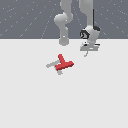

In [ ]:
AUDIT_SOURCE = 'import ast, importlib.util, json, os, sys\nfrom pathlib import Path\nimport gymnasium as gym\nimport torch\nfrom PIL import Image\nimport mani_skill.envs\nfrom mani_skill.utils.wrappers.flatten import FlattenRGBDObservationWrapper\n\noutput = Path(sys.argv[1])\noutput.mkdir(parents=True, exist_ok=True)\nroot = Path(os.environ["MANISKILL_ROOT"])\nbaseline_path = root / "examples/baselines/ppo/ppo_rgb.py"\nspec = importlib.util.spec_from_file_location("audited_rgb_ppo", baseline_path)\nbaseline = importlib.util.module_from_spec(spec)\nsys.modules[spec.name] = baseline\nspec.loader.exec_module(baseline)\nassert baseline.Args().control_mode == "pd_joint_delta_pos"\nassert baseline.Args().include_state is True\nassert baseline.Args().learning_rate == 3e-4\n\n# Read the exact checkout\'s command rather than assuming current web docs match it.\ncommands = (root / "examples/baselines/ppo/baselines.sh").read_text().replace("\\\\\\n", " ")\nmatching = [line.strip() for line in commands.splitlines()\n            if "ppo_rgb.py" in line and "PushT-v1" in line]\nprint("Pinned checkout\'s RGB Push-T command:")\nprint("\\n".join(matching) or "No matching command found; inspect baselines.sh")\n\nenv = gym.make("PushT-v1", num_envs=1, obs_mode="rgb", render_mode="rgb_array",\n               sim_backend="physx_cuda", control_mode="pd_joint_delta_pos")\ntry:\n    raw, _ = env.reset(seed=17)\n    agent_keys = set(raw["agent"])\n    extra_keys = set(raw["extra"])\n    assert {"qpos", "qvel"} <= agent_keys\n    assert agent_keys <= {"qpos", "qvel", "controller"}, agent_keys\n    assert extra_keys == {"tcp_pose"}, f"Unexpected RGB task inputs: {extra_keys}"\n    assert set(raw["sensor_data"]) == {"base_camera"}\n    robot_keys = sorted(agent_keys)\n    expected_parts = [raw["agent"]["qpos"], raw["agent"]["qvel"], raw["extra"]["tcp_pose"]]\n    expected_width = sum(x.shape[-1] for x in expected_parts)\n    # Permit only empty controller-state dictionaries for this comparison.\n    assert not raw["agent"].get("controller", {}), "Inspect additional controller-state inputs"\n    expected_values = torch.cat(expected_parts, dim=-1)\n    wrapped = FlattenRGBDObservationWrapper(env, rgb=True, depth=False, state=True)\n    obs, _ = wrapped.reset(seed=17)\n    assert set(obs) == {"rgb", "state"}\n    assert obs["rgb"].ndim == 4 and obs["rgb"].shape[-1] == 3\n    assert obs["state"].shape[-1] == expected_width\n    # Compare values independent of field ordering; the original wrapper owns ordering.\n    assert torch.allclose(obs["state"].sort(-1).values, expected_values.sort(-1).values, atol=1e-5)\n    agent = baseline.Agent(wrapped, sample_obs=obs).cuda().eval()\n    with torch.no_grad():\n        action = agent.get_action(obs, deterministic=True)\n        value = agent.get_value(obs)\n    assert torch.isfinite(action).all() and torch.isfinite(value).all()\n    assert action.shape == (1, *env.unwrapped.single_action_space.shape)\n    Image.fromarray(obs["rgb"][0].cpu().numpy().astype("uint8")).save(output / "policy_camera.png")\n    for _ in range(5):\n        obs, reward, _, _, _ = wrapped.step(torch.zeros_like(action))\n        assert torch.isfinite(reward).all()\n    import inspect\n    contract = {\n        "env_id": "PushT-v1", "controller": "pd_joint_delta_pos",\n        "robot_fields": robot_keys, "extra_fields": sorted(extra_keys),\n        "policy_inputs": {k: list(v.shape[1:]) for k,v in obs.items()},\n        "object_and_goal_numeric_inputs": False,\n        "actor_critic_share_observation_encoder": True,\n        "action_low": env.unwrapped.single_action_space.low.tolist(),\n        "action_high": env.unwrapped.single_action_space.high.tolist(),\n        "control_frequency": getattr(env.unwrapped, "control_freq", None),\n        "max_episode_steps": env.spec.max_episode_steps,\n        "reward_mode": getattr(env.unwrapped, "reward_mode", None),\n        "defaults": vars(baseline.Args()),\n        "verified": True,\n    }\n    (output / "observation_contract.json").write_text(json.dumps(contract, indent=2))\n    (output / "observation_wrapper.py").write_text(inspect.getsource(FlattenRGBDObservationWrapper))\n    (output / "task_success_definition.py").write_text(inspect.getsource(env.unwrapped.evaluate))\n    print(json.dumps(contract, indent=2))\nfinally:\n    env.close()\n'
AUDIT_SCRIPT = WORK_ROOT / "audit_joint_rgb.py"
AUDIT_SCRIPT.write_text(AUDIT_SOURCE)
shutil.copy2(AUDIT_SCRIPT, OUTPUT_ROOT / AUDIT_SCRIPT.name)
PREFLIGHT = OUTPUT_ROOT / "preflight"
checked([TRAIN_PY, AUDIT_SCRIPT, PREFLIGHT])
contract = json.loads((PREFLIGHT / "observation_contract.json").read_text())
assert contract["verified"]
from IPython.display import display, Image, HTML
print("Actual model input shapes:", contract["policy_inputs"])
display(Image(filename=str(PREFLIGHT / "policy_camera.png"), width=384))


## 4. Progress display, evaluation CSV, and training command

The monitor only reads the baseline's output. It does not alter PPO, observations, rewards, or checkpoint saving. The bar advances when an iteration has finished and retains **both success rates, return, and SPS simultaneously**. During evaluation or the first rollout it may pause while the process works.

`success` means success at any point in an episode; `end` means success at the final step. Each periodic evaluation uses 16 environments for 100 steps, normally 16 complete episodes with this task's horizon. The CSV includes the actual episode count reported by the baseline. Displayed statistics are the latest evaluation, not a running average across all training.


In [ ]:
MONITOR_SOURCE = '"""Monitor the unchanged ManiSkill PPO process; retain logs and evaluation CSV.\n\nThis file does not import or modify the simulator or training algorithm.\n"""\n\nimport csv\nimport json\nfrom pathlib import Path\nimport re\nimport subprocess\nimport time\nfrom collections import deque\n\n\nEVALUATION_FIELDS = (\n    "iteration", "steps", "episodes", "success_once", "success_at_end", "return"\n)\n\n\nclass PPOLogParser:\n    def __init__(self):\n        self.iteration = 0\n        self.steps = 0\n        self.current = {}\n        self.latest = {}\n\n    def feed(self, line):\n        line = line.strip()\n        match = re.search(r"Epoch:\\s*(\\d+),\\s*global_step=(\\d+)", line)\n        if match:\n            self.iteration, self.steps = map(int, match.groups())\n            self.current = {}\n        match = re.search(r"resulting in (\\d+) episodes", line)\n        if match:\n            self.current["episodes"] = int(match.group(1))\n        match = re.fullmatch(r"eval_(success_once|success_at_end|return)_mean=(\\S+)", line)\n        if match:\n            key, value = match.groups()\n            self.current[key] = float(value)\n            self.latest[key] = float(value)\n            if key == "success_at_end":\n                return dict(iteration=self.iteration, steps=self.steps,\n                            **{k: self.current.get(k, "") for k in EVALUATION_FIELDS[2:]})\n        if line.startswith("SPS:"):\n            self.latest["SPS"] = int(line.split(":", 1)[1])\n        return None\n\n    def postfix(self):\n        return {\n            "success": f"{self.latest[\'success_once\']:.0%}" if "success_once" in self.latest else "pending",\n            "end": f"{self.latest[\'success_at_end\']:.0%}" if "success_at_end" in self.latest else "pending",\n            "return": f"{self.latest[\'return\']:.2f}" if "return" in self.latest else "pending",\n            "SPS": self.latest.get("SPS", "pending"),\n        }\n\n\ndef stop_process(process):\n    if process.poll() is None:\n        process.terminate()\n        try:\n            process.wait(timeout=15)\n        except subprocess.TimeoutExpired:\n            process.kill()\n            process.wait()\n\n\ndef run_training(command, output_root, run_name, total_steps, batch_size,\n                 metadata=None, progress_factory=None):\n    """Run one training job, progressing only when an iteration has completed."""\n    if progress_factory is None:\n        from tqdm.auto import tqdm\n        progress_factory = tqdm\n    output_root = Path(output_root)\n    command = list(map(str, command))\n    if batch_size <= 0 or total_steps < batch_size:\n        raise ValueError("Training budget must contain at least one full batch")\n    effective_steps = (total_steps // batch_size) * batch_size\n    run_dir = output_root / "runs" / run_name\n    if run_dir.exists():\n        raise FileExistsError(f"Refusing to overwrite {run_dir}; use a new run name")\n    output_root.mkdir(parents=True, exist_ok=True)\n    # Reserve the name before starting, even if initialization later fails.\n    run_dir.mkdir(parents=True)\n    record = dict(metadata or {}, command=command, requested_steps=total_steps,\n                  effective_steps=effective_steps, batch_size=batch_size)\n    (run_dir / "run_config.json").write_text(json.dumps(record, indent=2))\n    log_path = run_dir / "train.log"\n    csv_path = run_dir / "evaluations.csv"\n    parser = PPOLogParser()\n    tail = deque(maxlen=50)\n    start = time.monotonic()\n    print(f"Logs/checkpoints: {run_dir}", flush=True)\n    print(f"Budget: {total_steps:,} requested; {effective_steps:,} executed in full batches", flush=True)\n    with log_path.open("w") as log, csv_path.open("w", newline="") as metrics:\n        writer = csv.DictWriter(metrics, fieldnames=EVALUATION_FIELDS)\n        writer.writeheader()\n        metrics.flush()\n        with progress_factory(total=effective_steps, desc=run_name, unit="transition",\n                              unit_scale=True, mininterval=1) as progress:\n            process = subprocess.Popen(command, cwd=output_root, stdout=subprocess.PIPE,\n                                       stderr=subprocess.STDOUT, text=True, bufsize=1)\n            try:\n                for line in process.stdout:\n                    log.write(line)\n                    log.flush()\n                    tail.append(line.rstrip())\n                    row = parser.feed(line)\n                    completed = min(parser.steps, effective_steps)\n                    if completed > progress.n:\n                        progress.update(completed - progress.n)\n                    if row:\n                        writer.writerow(row)\n                        metrics.flush()\n                    if row or line.startswith("SPS:"):\n                        progress.set_postfix(parser.postfix(), refresh=False)\n                code = process.wait()\n                if code:\n                    raise RuntimeError(f"PPO exited with {code}. Log: {log_path}\\n" + "\\n".join(tail))\n                final = run_dir / "final_ckpt.pt"\n                if not final.is_file():\n                    raise RuntimeError(f"Process finished without {final}.\\n" + "\\n".join(tail))\n                progress.update(effective_steps - progress.n)\n            except BaseException:\n                stop_process(process)\n                raise\n            finally:\n                process.stdout.close()\n    elapsed = time.monotonic() - start\n    (run_dir / "completion.json").write_text(json.dumps({\n        "elapsed_seconds": elapsed, "effective_steps": effective_steps,\n        "transitions_per_second": effective_steps / elapsed,\n        "latest_evaluation": parser.latest,\n        "note": "The final checkpoint may be newer than the latest periodic evaluation.",\n    }, indent=2))\n    print(f"Finished in {elapsed / 3600:.2f} hours; {effective_steps / elapsed:.0f} transitions/s")\n    print(f"Checkpoint: {final}\\nEvaluation history: {csv_path}")\n    return run_dir\n'
MONITOR_PATH = WORK_ROOT / "ppo_progress.py"
MONITOR_PATH.write_text(MONITOR_SOURCE)
shutil.copy2(MONITOR_PATH, OUTPUT_ROOT / MONITOR_PATH.name)
# Import from the embedded source, independent of any previous notebook module cache.
monitor_namespace = {"__name__": "joint_ppo_monitor"}
exec(compile(MONITOR_SOURCE, str(MONITOR_PATH), "exec"), monitor_namespace)
run_training = monitor_namespace["run_training"]

BATCH_SIZE = NUM_ENVS * NUM_STEPS
assert BATCH_SIZE % NUM_MINIBATCHES == 0
assert BATCH_SIZE // NUM_MINIBATCHES >= 2
assert EVAL_FREQ > 1

def make_command(name, total, num_envs=None, minibatches=None,
                 epochs=None, eval_envs=None, eval_freq=None):
    # Resolve at call time so rerunning configuration cannot leave stale defaults.
    num_envs = NUM_ENVS if num_envs is None else num_envs
    minibatches = NUM_MINIBATCHES if minibatches is None else minibatches
    epochs = UPDATE_EPOCHS if epochs is None else epochs
    eval_envs = NUM_EVAL_ENVS if eval_envs is None else eval_envs
    eval_freq = EVAL_FREQ if eval_freq is None else eval_freq
    assert num_envs * NUM_STEPS % minibatches == 0
    assert num_envs * NUM_STEPS // minibatches >= 2
    assert total >= num_envs * NUM_STEPS and eval_freq > 1
    return list(map(str, [
        TRAIN_PY, BASELINE,
        "--env-id", "PushT-v1", "--control-mode", "pd_joint_delta_pos",
        "--include-state", "--seed", SEED, "--exp-name", name,
        "--num-envs", num_envs, "--num-steps", NUM_STEPS,
        "--num-minibatches", minibatches, "--update-epochs", epochs,
        "--total-timesteps", total, "--gamma", 0.99,
        "--learning-rate", 3e-4,
        "--num-eval-envs", eval_envs, "--num-eval-steps", 100,
        "--eval-freq", eval_freq,
        "--save-model", "--no-track", "--no-capture-video",
    ]))

metadata = {
    "maniskill_commit": actual_commit, "baseline_sha256": BASELINE_SHA256,
    "observation_contract": contract, "training_python": str(TRAIN_PY),
    "initialization": "random; no checkpoint or optimizer warm start",
}
print("Main command:", shlex.join(make_command(RUN_NAME, TOTAL_TRANSITIONS)))


def validate_main_command(command):
    expected = {
        "--env-id": "PushT-v1", "--control-mode": "pd_joint_delta_pos",
        "--seed": "1", "--num-envs": "1024", "--num-steps": "16",
        "--num-minibatches": "32", "--update-epochs": "8",
        "--total-timesteps": "50000000", "--gamma": "0.99",
        "--learning-rate": "0.0003", "--num-eval-envs": "16",
        "--num-eval-steps": "100", "--eval-freq": "25",
    }
    for flag, value in expected.items():
        assert command.count(flag) == 1, f"Missing or repeated {flag}"
        actual = command[command.index(flag) + 1]
        assert actual == value, f"{flag}: expected {value}, got {actual}"
    for flag in ("--include-state", "--save-model", "--no-track", "--no-capture-video"):
        assert flag in command, f"Missing {flag}"
    assert "--checkpoint" not in command and "--evaluate" not in command
    assert command[:2] == [str(TRAIN_PY), str(BASELINE)]
    assert command[command.index("--exp-name") + 1] == RUN_NAME
    batch_size = int(expected["--num-envs"]) * int(expected["--num-steps"])
    assert batch_size // int(expected["--num-minibatches"]) == 512
    return batch_size


Main command: /content/pusht_camera_ppo/python311/bin/python /content/ManiSkill/examples/baselines/ppo/ppo_rgb.py --env-id PushT-v1 --control-mode pd_joint_delta_pos --include-state --seed 1 --exp-name rgb_joint_seed1_50m_mb32 --num-envs 1024 --num-steps 16 --num-minibatches 32 --update-epochs 8 --total-timesteps 50000000 --gamma 0.99 --learning-rate 0.0003 --num-eval-envs 16 --num-eval-steps 100 --eval-freq 25 --save-model --no-track --no-capture-video


## 5. Small smoke test

This validates the original baseline with our installed runtime. It uses eight environments and four PPO iterations. It should produce a checkpoint, not a competent teacher. The main run starts independently from random weights and does not load these smoke weights.


In [ ]:
SMOKE_DIR = run_training(
    make_command("joint_smoke", 512, num_envs=8, minibatches=2, epochs=1, eval_envs=1, eval_freq=2),
    OUTPUT_ROOT, "joint_smoke", total_steps=512, batch_size=8 * NUM_STEPS,
    metadata=metadata,
)
SMOKE_OK = (SMOKE_DIR / "final_ckpt.pt").is_file()


Logs/checkpoints: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/joint_smoke
Budget: 512 requested; 512 executed in full batches


joint_smoke:   0%|          | 0.00/512 [00:00<?, ?transition/s]

Finished in 0.00 hours; 30 transitions/s
Checkpoint: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/joint_smoke/final_ckpt.pt
Evaluation history: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/joint_smoke/evaluations.csv


## 6. Train for 50M transitions

Run this cell when the observation check and smoke test pass. It starts **one fresh uninterrupted job** with the settings printed above. The task reward is unchanged. Checkpoints and logs are written directly to Drive. No previous teacher weights are loaded.

The upstream baseline saves model weights periodically, but not optimizer, RNG, or environment state. If Colab disconnects, saved weights remain usable; restarting from them is a warm start rather than an exact continuation. At the earlier run's roughly 1,950 transitions/s, 50M would take about seven hours; actual throughput and Colab runtime availability can differ. This notebook does not keep Colab alive or schedule a background run.

With the default batch, evaluation/checkpoint saving happens approximately every 409,600 training transitions. `ckpt_1.pt` is before any training. The final checkpoint is newer than the last periodic evaluation and needs its own evaluation afterward.

The launch cell checks the actual command for 1024 environments and 32 minibatches before starting. Both `success` (ever successful in an episode) and `end` (successful on its final step) remain visible on tqdm between evaluations, alongside return and SPS.


In [ ]:
assert SMOKE_OK and contract["verified"]
command = make_command(RUN_NAME, TOTAL_TRANSITIONS)
BATCH_SIZE = validate_main_command(command)
assert Path(TRAIN_PY).is_file(), "Run the setup cell to restore Python 3.11."
assert Path(BASELINE).is_file(), "Run the setup cell to restore ManiSkill."
assert hashlib.sha256(Path(BASELINE).read_bytes()).hexdigest() == BASELINE_SHA256
print("Launching:", shlex.join(command))
print(f"Rollout batch: {BATCH_SIZE:,}; minibatches: 32; samples/minibatch: 512")
TRAIN_DIR = run_training(
    command, OUTPUT_ROOT, RUN_NAME,
    total_steps=int(command[command.index("--total-timesteps") + 1]),
    batch_size=BATCH_SIZE, metadata=metadata,
)


Launching: /content/pusht_camera_ppo/python311/bin/python /content/ManiSkill/examples/baselines/ppo/ppo_rgb.py --env-id PushT-v1 --control-mode pd_joint_delta_pos --include-state --seed 1 --exp-name rgb_joint_seed1_50m_mb32 --num-envs 1024 --num-steps 16 --num-minibatches 32 --update-epochs 8 --total-timesteps 50000000 --gamma 0.99 --learning-rate 0.0003 --num-eval-envs 16 --num-eval-steps 100 --eval-freq 25 --save-model --no-track --no-capture-video
Rollout batch: 16,384; minibatches: 32; samples/minibatch: 512
Logs/checkpoints: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/rgb_joint_seed1_50m_mb32
Budget: 50,000,000 requested; 49,987,584 executed in full batches


rgb_joint_seed1_50m_mb32:   0%|          | 0.00/50.0M [00:00<?, ?transition/s]

Finished in 3.77 hours; 3679 transitions/s
Checkpoint: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/rgb_joint_seed1_50m_mb32/final_ckpt.pt
Evaluation history: /content/drive/MyDrive/182_final_project/camera_ppo_joint/20261121T212436151405Z/runs/rgb_joint_seed1_50m_mb32/evaluations.csv


## 7. Review success rates across stages

This cell reads the persistent CSV, including partial results if a job was interrupted. Rates come from periodic validation starts, and should not be interpreted as final independent test accuracy. Use environment transitions when comparing with published plots, not PPO iteration number.


In [ ]:
metrics_path = OUTPUT_ROOT / "runs" / RUN_NAME / "evaluations.csv"
with metrics_path.open() as f:
    evaluations = list(csv.DictReader(f))
print(f"{'Iteration':>9} {'Transitions':>13} {'Episodes':>8} {'Success':>9} {'End':>9} {'Return':>9}")
for row in evaluations:
    print(f"{int(row['iteration']):9d} {int(row['steps']):13,d} {row['episodes']:>8} "
          f"{float(row['success_once']):9.1%} {float(row['success_at_end']):9.1%} {float(row['return']):9.2f}")


Iteration   Transitions Episodes   Success       End    Return
        1             0       16      0.0%      0.0%     13.16
       26       409,600       16      0.0%      0.0%     13.51
       51       819,200       16      0.0%      0.0%     14.69
       76     1,228,800       16      0.0%      0.0%     13.24
      101     1,638,400       16      0.0%      0.0%     11.14
      126     2,048,000       16      0.0%      0.0%     15.12
      151     2,457,600       16      0.0%      0.0%     13.75
      176     2,867,200       16      0.0%      0.0%     13.45
      201     3,276,800       16      0.0%      0.0%     13.42
      226     3,686,400       16      0.0%      0.0%     15.61
      251     4,096,000       16      0.0%      0.0%     16.32
      276     4,505,600       16      0.0%      0.0%     14.08
      301     4,915,200       16      0.0%      0.0%     16.40
      326     5,324,800       16      0.0%      0.0%     13.78
      351     5,734,400       16      0.0%      0.0%   

In [ ]:
from pathlib import Path
import subprocess, re, csv, datetime

run_dir = Path(OUTPUT_ROOT) / "runs" / RUN_NAME
result_dir = run_dir / (
    "checkpoint_comparison_" +
    datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
)
result_dir.mkdir(parents=True, exist_ok=True)

candidates = [
    "ckpt_2726.pt",
    "ckpt_2776.pt",
    "ckpt_2901.pt",
    "final_ckpt.pt",
]
rows = []

for filename in candidates:
    checkpoint = run_dir / filename
    if not checkpoint.is_file():
        print(f"Skipping missing checkpoint: {filename}")
        continue

    command = make_command(
        f"compare_{checkpoint.stem}", 16,
        num_envs=1, minibatches=1, epochs=1, eval_envs=10,
    )
    for flag, value in {
        "--seed": "1001",
        "--num-eval-steps": "1000",  # 10 envs × 10 episodes × 100 steps
    }.items():
        command[command.index(flag) + 1] = value
    command += ["--evaluate", "--checkpoint", str(checkpoint)]

    print(f"\nEvaluating {filename} ...", flush=True)
    metrics = {}
    episodes = None
    log_path = result_dir / f"{checkpoint.stem}.log"

    with log_path.open("w") as log:
        process = subprocess.Popen(
            list(map(str, command)), cwd=OUTPUT_ROOT,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1,
        )
        try:
            for line in process.stdout:
                log.write(line)
                log.flush()
                match = re.search(r"resulting in (\d+) episodes", line)
                if match:
                    episodes = int(match.group(1))
                    print(line.strip(), flush=True)
                match = re.fullmatch(
                    r"eval_(success_once|success_at_end|return)_mean=(\S+)",
                    line.strip(),
                )
                if match:
                    metrics[match.group(1)] = float(match.group(2))
                    print(line.strip(), flush=True)
            code = process.wait()
        finally:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=15)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
            process.stdout.close()

    if code != 0:
        raise RuntimeError(f"Evaluation failed. See {log_path}")
    if not {"success_once", "success_at_end", "return"} <= metrics.keys():
        raise RuntimeError(f"Missing evaluation metrics. See {log_path}")
    if episodes != 100:
        raise RuntimeError(f"Expected 100 episodes, got {episodes}. See {log_path}")

    rows.append({"checkpoint": filename, "episodes": episodes, **metrics})
    with (result_dir / "comparison.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

if not rows:
    raise FileNotFoundError(f"No candidate checkpoints found in {run_dir}")

ranked = sorted(
    rows,
    key=lambda r: (r["success_at_end"], r["success_once"], r["return"]),
    reverse=True,
)
print(f"\n{'Checkpoint':<22} {'Episodes':>8} {'Success':>10} {'End':>10} {'Return':>10}")
for row in ranked:
    print(
        f"{row['checkpoint']:<22} {row['episodes']:>8} "
        f"{row['success_once']:>9.1%} {row['success_at_end']:>9.1%} "
        f"{row['return']:>10.2f}"
    )

SELECTED_CHECKPOINT = run_dir / ranked[0]["checkpoint"]
print("\nSelected by end success, then success-once, then return:")
print(SELECTED_CHECKPOINT)
print("Results saved to:", result_dir)
print("These are validation results; use fresh seeds for the final test.")


Evaluating ckpt_2726.pt ...
Evaluated 10000 steps resulting in 100 episodes
eval_success_once_mean=0.9300000071525574
eval_return_mean=59.02802658081055
eval_success_at_end_mean=0.9199999570846558

Evaluating ckpt_2776.pt ...
Evaluated 10000 steps resulting in 100 episodes
eval_success_once_mean=0.9699999690055847
eval_return_mean=61.60700225830078
eval_success_at_end_mean=0.9599999785423279

Evaluating ckpt_2901.pt ...
Evaluated 10000 steps resulting in 100 episodes
eval_success_once_mean=0.9899999499320984
eval_return_mean=59.94911575317383
eval_success_at_end_mean=0.8899999856948853

Evaluating final_ckpt.pt ...
Evaluated 10000 steps resulting in 100 episodes
eval_success_once_mean=1.0
eval_return_mean=57.54354476928711
eval_success_at_end_mean=0.7599999904632568

Checkpoint             Episodes    Success        End     Return
ckpt_2776.pt                100     97.0%     96.0%      61.61
ckpt_2726.pt                100     93.0%     92.0%      59.03
ckpt_2901.pt                10

## 8. Evaluate the final teacher on fresh starts (optional)

This uses the **original RGB script and joint controller**, matching training. With 10 environments and 1,000 steps each, the 100-step horizon normally yields 100 episodes; inspect the printed actual count. It uses a different seed from training/periodic validation. Run only after training has exited so the jobs do not compete for memory. Video recording stays off for this statistics-only evaluation.


In [ ]:
FINAL_CHECKPOINT = OUTPUT_ROOT / "runs" / RUN_NAME / "final_ckpt.pt"
assert FINAL_CHECKPOINT.is_file()
RUN_FINAL_EVALUATION = False
if RUN_FINAL_EVALUATION:
    evaluation_command = make_command("final_eval", 16, num_envs=1, minibatches=1,
                                      epochs=1, eval_envs=10)
    evaluation_command[evaluation_command.index("--seed") + 1] = "1001"
    evaluation_command[evaluation_command.index("--num-eval-steps") + 1] = "1000"
    evaluation_command += ["--evaluate", "--checkpoint", str(FINAL_CHECKPOINT)]
    (FINAL_CHECKPOINT.parent / "final_evaluation_command.json").write_text(json.dumps(evaluation_command, indent=2))
    checked(evaluation_command, cwd=OUTPUT_ROOT)
else:
    print("Set RUN_FINAL_EVALUATION=True to evaluate the final checkpoint.")


## 9. Record and view five rollouts (optional)

Use the original script for these checkpoints; the old custom observation adapter is incompatible. This evaluates without further training. Videos and diagnostic trajectory files are placed in `test_videos` beside the checkpoint; these are not the finalized ICL dataset. The displayed video can use the task's render view, whose resolution/framing differs from the policy's camera. Raw MP4 bytes are embedded directly to avoid the earlier notebook `Video(filename=...)` error.


In [ ]:
RUN_VIDEO_EVALUATION = False
if RUN_VIDEO_EVALUATION:
    assert FINAL_CHECKPOINT.is_file()
    video_command = make_command("video_eval", 16, num_envs=1, minibatches=1,
                                 epochs=1, eval_envs=1)
    video_command.remove("--no-capture-video")
    video_command[video_command.index("--seed") + 1] = "101"
    video_command[video_command.index("--num-eval-steps") + 1] = "500"
    video_command += ["--evaluate", "--checkpoint", str(FINAL_CHECKPOINT),
                      "--capture-video", "--render-mode", "rgb_array"]
    checked(video_command, cwd=OUTPUT_ROOT)
else:
    print("Set RUN_VIDEO_EVALUATION=True to record rollouts after training.")


In [ ]:
import base64
video_dir = OUTPUT_ROOT / "runs" / RUN_NAME / "test_videos"
for path in sorted(video_dir.rglob("*.mp4")):
    print(path.name)
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    display(HTML('<video width="640" controls playsinline>'
                 f'<source src="data:video/mp4;base64,{encoded}" type="video/mp4"></video>'))


## Optional TensorBoard

The training bar and CSV already report success rates. TensorBoard provides additional loss, entropy, KL, and explained-variance curves. It runs under the same Python 3.11 environment, avoiding notebook-kernel package mismatches. Run this after the long cell finishes, or from another cell when your notebook interface supports it.


In [ ]:
# TensorBoard runs under Python 3.11 too; no dependency on the
# notebook kernel's installed TensorBoard version.
if "tensorboard_process" in globals() and tensorboard_process.poll() is None:
    print("TensorBoard is already running.")
else:
    tensorboard_log = (OUTPUT_ROOT / "tensorboard-server.log").open("a")
    tensorboard_process = subprocess.Popen(
        [str(TRAIN_PY), "-m", "tensorboard.main", "--logdir", str(OUTPUT_ROOT / "runs"),
         "--host", "0.0.0.0", "--port", "6006"],
        stdout=tensorboard_log, stderr=subprocess.STDOUT)
    time.sleep(3)
    if tensorboard_process.poll() is not None:
        tensorboard_log.close()
        raise RuntimeError((OUTPUT_ROOT / "tensorboard-server.log").read_text())
from google.colab import output
output.serve_kernel_port_as_iframe(6006, height=650)
print("Saved checkpoints:")
for path in sorted((OUTPUT_ROOT / "runs").glob("*/*.pt")):
    print(path.relative_to(OUTPUT_ROOT))


## Notes and validation status

This notebook preserves the original baseline algorithm. It does not demonstrate teacher competence until evaluation succeeds, and it does not yet produce multiple teachers or train the ICL learner. Use the same controller and robot information in a matching state-based comparison; exclude RGB there and supply object/goal state explicitly.

Offline checks cover Python syntax, embedded helper consistency, command arguments, log parsing, simultaneous success-rate display, CSV output, and handling of process failures. The earlier Colab run established that the pinned Python environment works for the old setup. This new notebook still requires its own observation and GPU smoke checks; no claim is made that its 50M run has already been executed.

Sources: [RGB PPO](https://github.com/mani-skill/ManiSkill/blob/v3.0.1/examples/baselines/ppo/ppo_rgb.py), [baseline commands](https://github.com/mani-skill/ManiSkill/blob/v3.0.1/examples/baselines/ppo/baselines.sh), [installation](https://maniskill.readthedocs.io/en/latest/user_guide/getting_started/installation.html).
